# 06 - Label Readiness, Spatial Duplicates & Hourly Dynamics

**Title**: `06_label_readiness_and_duplicates.ipynb`  
**Purpose**: Analyze high-resolution hourly precipitation coupling, audit administrative ticket maturity and resolution latency, evaluate chained vs. non-chaining spatial clustering for duplicate detection, and assess reporting channel/location coverage.  
**Inputs**: `data/processed/complaints_clean.csv`, `data/processed/rain_hourly_brooklyn.csv`, saved diagnostic tables `t24_*.csv` in `data/processed/report_tables/`  
**Outputs**: Hourly flood-rain lag/rolling correlation table, daily correlation summary, storm-day hourly profile, chained and alternative duplicate cluster statistics, spatial spread quantiles, channel/location distributions, monthly/weekly label readiness profiles.  
**Runtime**: ~20-30 seconds

In [1]:
import sys; from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()); sys.path.insert(0, str(ROOT))
from src.nbutils import Checker, md
RUN_HEAVY = False
RUN_API = False

In [2]:
import pandas as pd
import numpy as np
import importlib
import src.preprocessing.label_readiness as lr_module
importlib.reload(lr_module)
from src.preprocessing.label_readiness import (
    build_hourly_flood_rain, compute_hourly_correlations, compute_daily_correlations,
    compute_storm_days_summary, compute_weak_clusters_chained, compute_cluster_alternatives,
    compute_spatial_spread, compute_coord_duplicates, compute_distinct_coordinates,
    compute_channel_and_location_stats, compute_label_readiness_tables
)

clean_csv_path = ROOT / "data" / "processed" / "complaints_clean.csv"
rain_hourly_path = ROOT / "data" / "processed" / "rain_hourly_brooklyn.csv"

print(f"Loading {clean_csv_path.relative_to(ROOT)} and {rain_hourly_path.relative_to(ROOT)}...")
df_clean = pd.read_csv(
    clean_csv_path,
    dtype={"id": str, "resolution_id": str},
    keep_default_na=False,
)
df_rain_hourly = pd.read_csv(rain_hourly_path)

n_rain_rows = len(df_rain_hourly)
n_rain_nulls = int(df_rain_hourly.isna().sum().sum())
print(f"Hourly rain dataset: {n_rain_rows:,} rows | {n_rain_nulls} null values")

df_hourly = build_hourly_flood_rain(df_clean, df_rain_hourly)
n_hours_flood_ge1 = int((df_hourly["flood_count"] >= 1).sum())

# Independent second computation: count unique truncated hours directly from df_clean flood rows
df_flood_rows = df_clean[df_clean["group"] == "flood"].copy()
df_flood_rows["hour_str"] = pd.to_datetime(df_flood_rows["timestamp"]).dt.strftime("%Y-%m-%d %H")
n_hours_flood_alt = int(df_flood_rows["hour_str"].nunique())
n_flood_complaints = len(df_flood_rows)

print(f"Constructed continuous hourly dataset: {len(df_hourly):,} hours | hours with >= 1 flood complaint: {n_hours_flood_ge1:,}")
print(f"Independent computation: {n_flood_complaints:,} flood complaints across {n_hours_flood_alt:,} distinct hours")

Loading data\processed\complaints_clean.csv and data\processed\rain_hourly_brooklyn.csv...


Hourly rain dataset: 8,760 rows | 0 null values


Constructed continuous hourly dataset: 8,760 hours | hours with >= 1 flood complaint: 2,705
Independent computation: 5,520 flood complaints across 2,705 distinct hours


In [3]:
hourly_corr_df = compute_hourly_correlations(df_hourly)
daily_corr_df = compute_daily_correlations(df_hourly)

print("=== Table T24_1d: Hourly Flood Count vs. Precipitation Correlations ===")
print(hourly_corr_df.to_string(index=False))

print("\n=== Table T24_1e: Daily Aggregated Correlations ===")
print(daily_corr_df.to_string(index=False))

h_p_lag0 = float(hourly_corr_df.loc[hourly_corr_df["feature"] == "rain_lag_0h", "pearson_r"].values[0])
h_p_roll3 = float(hourly_corr_df.loc[hourly_corr_df["feature"] == "rain_rolling_3h", "pearson_r"].values[0])
h_p_roll24 = float(hourly_corr_df.loc[hourly_corr_df["feature"] == "rain_rolling_24h", "pearson_r"].values[0])
h_s_lag0 = float(hourly_corr_df.loc[hourly_corr_df["feature"] == "rain_lag_0h", "spearman_r"].values[0])

d_p_sum = float(daily_corr_df.loc[daily_corr_df["metric"] == "rain_sum", "pearson_r"].values[0])
d_p_max = float(daily_corr_df.loc[daily_corr_df["metric"] == "rain_max_hourly", "pearson_r"].values[0])
d_p_ge5 = float(daily_corr_df.loc[daily_corr_df["metric"] == "rain_hours_ge_5mm", "pearson_r"].values[0])

=== Table T24_1d: Hourly Flood Count vs. Precipitation Correlations ===
         feature  n_hours  pearson_r pearson_p  spearman_r spearman_p
     rain_lag_0h     8760     0.2689 6.38e-145      0.1727   1.35e-59
     rain_lag_1h     8759     0.2671 6.11e-143      0.1687   6.78e-57
     rain_lag_2h     8758     0.2396 1.52e-114      0.1534   2.78e-47
     rain_lag_3h     8757     0.1999  1.16e-79      0.1546   5.34e-48
     rain_lag_6h     8754     0.1055  4.23e-23      0.1185   9.33e-29
 rain_rolling_3h     8760     0.3008 1.08e-182      0.1781   2.49e-63
 rain_rolling_6h     8760     0.2842 2.09e-162      0.1723   2.31e-59
rain_rolling_24h     8760     0.2384 2.06e-113      0.1735   3.73e-60

=== Table T24_1e: Daily Aggregated Correlations ===
           metric  pearson_r pearson_p  spearman_r spearman_p
         rain_sum     0.5614  1.06e-31      0.3417   1.97e-11
  rain_max_hourly     0.4538  6.03e-20      0.3560   2.40e-12
rain_hours_ge_5mm     0.3029  3.51e-09      0.2871   2.33e-

=== Table T24_1c: Peak Precipitation Event Day Dynamics ===
      date  daily_rain_sum_mm  max_hourly_rain_mm  hour_of_max_rain  max_hourly_flood_count  hour_of_max_flood  daily_flood_count
2026-05-20                7.2                 2.1                18                      63                 19                145
2026-05-21                7.2                 2.3                12                      21                 10                148
2026-07-06               49.6                 6.0                18                      39                 10                228


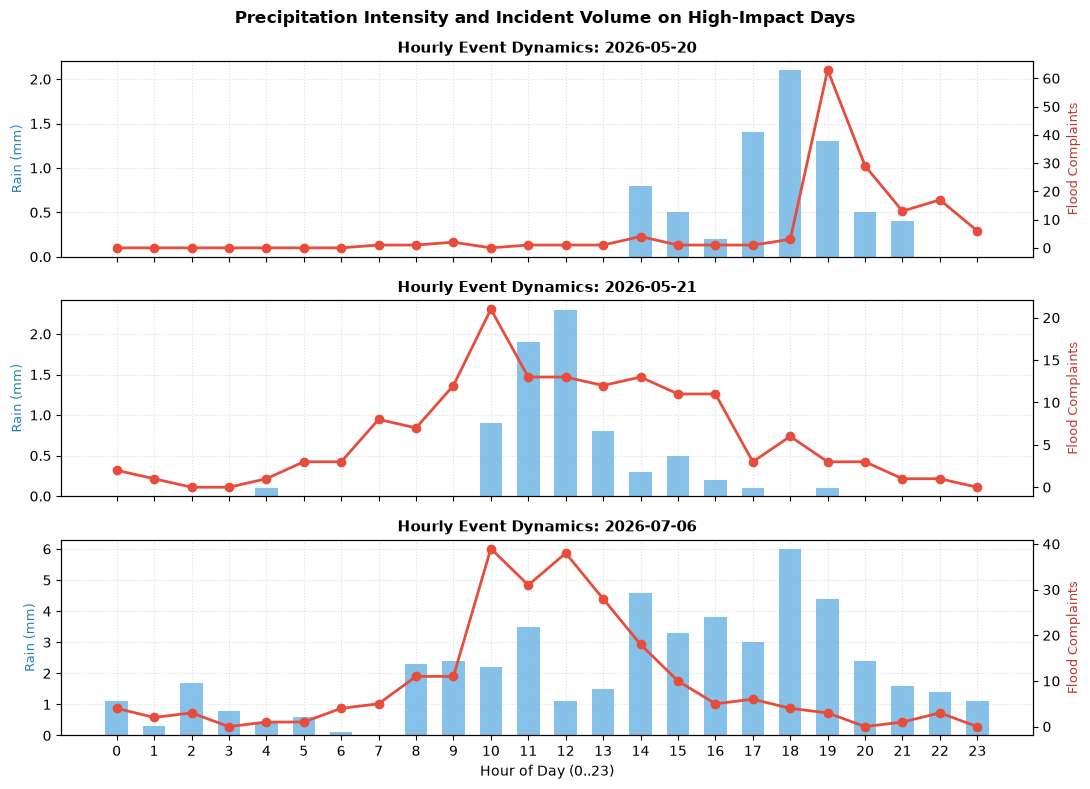

Saved figure: report\figures\06_storm_days_hourly.png


In [4]:
from src.preprocessing.label_readiness import plot_storm_days_hourly

target_storm_dates = ["2026-05-20", "2026-05-21", "2026-07-06"]
storm_summary_df = compute_storm_days_summary(df_hourly, target_storm_dates)

print("=== Table T24_1c: Peak Precipitation Event Day Dynamics ===")
print(storm_summary_df.to_string(index=False))

sd_dict = storm_summary_df.set_index("date").to_dict(orient="index")

fig1_path = ROOT / "report" / "figures" / "06_storm_days_hourly.png"
plot_storm_days_hourly(df_hourly, fig1_path, target_storm_dates)
print(f"Saved figure: {fig1_path.relative_to(ROOT)}")

In [5]:
clusters_summary_df, df_clustered = compute_weak_clusters_chained(df_clean)
cluster_alts = compute_cluster_alternatives(df_clean)

print("=== Table T24_2b: Chained Duplicate Clusters per Group (Gap <= 24h) ===")
print(clusters_summary_df.to_string(index=False))

cl_dict = clusters_summary_df.set_index("group").to_dict(orient="index")

print("\n=== Clustering Methodology Comparison: Maximum Cluster Size ===")
print(f"  Chained 24h Clustering     : {cl_dict['noise']['max_cluster_size']:,} rows")
print(f"  Alternative A (Calendar-Day): {cluster_alts['max_size_calendar_day']:,} rows")
print(f"  Alternative B (Anchor 24h)  : {cluster_alts['max_size_anchor_window']:,} rows")
print(f"  Alternative B execution     : {'Ran to completion' if cluster_alts.get('ran_anchor_window', True) else 'Skipped'}")

print("\n=== Clustering Methodology Comparison Table (Max Cluster Size & Count per Group) ===")
comp_tbl = cluster_alts.get("comparison_table")
if comp_tbl is not None:
    print(comp_tbl.to_string(index=False))
else:
    print("Methodology comparison completed.")

=== Table T24_2b: Chained Duplicate Clusters per Group (Gap <= 24h) ===
       group  rows_with_addr  n_clusters  clusters_ge_2  rows_in_clusters_ge_2  share_rows_ge_2_pct  size_2  size_3  size_4  size_5plus  max_cluster_size
       flood            4542        4171            245                    616                13.56     182      36      12          15                11
       noise          211011      139900          26560                  97671                46.29   16082    4935    2088        3455              8843
        road           10957        9802            776                   1931                17.62     570     119      43          44                12
sewer_backup            3006        2761            194                    439                14.60     158      30       2           4                 8

=== Clustering Methodology Comparison: Maximum Cluster Size ===
  Chained 24h Clustering     : 8,843 rows
  Alternative A (Calendar-Day): 90 rows
  Alternati

In [6]:
spread_df = compute_spatial_spread(df_clustered)
coord_dup_df = compute_coord_duplicates(df_clean)
distinct_coords_df = compute_distinct_coordinates(df_clean)

print("=== Table T24_2c: Spatial Spread Inside Clusters of Size >= 2 ===")
print(spread_df.to_string(index=False))

print("\n=== Table T24_2d: Coordinate-Level Duplicate Rates (Within 24h) ===")
print(coord_dup_df.to_string(index=False))

print("\n=== Table T24_2e: Distinct Coordinates per Group ===")
print(distinct_coords_df.to_string(index=False))

sp_dict = spread_df.set_index("group").to_dict(orient="index")
cd_dict = coord_dup_df.set_index("group").to_dict(orient="index")
dc_dict = dict(zip(distinct_coords_df["group"], distinct_coords_df["distinct_lat_lon_pairs"]))

=== Table T24_2c: Spatial Spread Inside Clusters of Size >= 2 ===
       group  n_clusters_ge_2  p50_dist_m  p90_dist_m  p99_dist_m  max_dist_m  clusters_le_0_5m  share_le_0_5m_pct
         ALL            27775         0.0        0.00      246.46    10062.13             27295              98.27
       flood              245         0.0        0.00     2800.23     4686.15               225              91.84
       noise            26560         0.0        0.00        0.00     9320.02             26396              99.38
        road              776         0.0     1804.35     6842.29    10062.13               480              61.86
sewer_backup              194         0.0        0.00        0.00        0.00               194             100.00

=== Table T24_2d: Coordinate-Level Duplicate Rates (Within 24h) ===
       group  total_rows  rows_with_coord_dup_24h  share_coord_dup_pct  dup_rows_with_address  share_dup_with_address_pct
       flood        5520                      826    

In [7]:
ch_df, loc_df, missing_loc_df = compute_channel_and_location_stats(df_clean)

print("=== Table T24_3: Top Submission Channels per Group (Sample) ===")
print(ch_df.head(10).to_string(index=False))

print("\n=== Table T24_3: Top Location Types per Group (Sample) ===")
print(loc_df.head(10).to_string(index=False))

print("\n=== Table T24_3: Missing Location Type Summary ===")
print(missing_loc_df.to_string(index=False))

mloc_dict = dict(zip(missing_loc_df["group"], missing_loc_df["missing_location_type_pct"]))

=== Table T24_3: Top Submission Channels per Group (Sample) ===
group  rank channel  count  share_pct
flood     1  ONLINE   2925      52.99
flood     2   PHONE   2388      43.26
flood     3   OTHER    207       3.75
noise     1  ONLINE 133217      62.88
noise     2  MOBILE  51529      24.32
noise     3   PHONE  27016      12.75
noise     4   OTHER     62       0.03
noise     5 UNKNOWN     19       0.01
 road     1 UNKNOWN   9544      59.14
 road     2  ONLINE   4203      26.04

=== Table T24_3: Top Location Types per Group (Sample) ===
group  rank              location_type  count  share_pct
flood     1                      Sewer   1605      29.08
flood     2                     Street    622      11.27
noise     1 Residential Building/House 115290      54.42
noise     2            Street/Sidewalk  53243      25.13
noise     3           Store/Commercial  10878       5.13
noise     4        Club/Bar/Restaurant   9124       4.31
noise     5 Building/Construction Site   2842       1.34
no

=== Table T24_4a: Monthly Label Maturity & Resolution Rates (Sample) ===
 month        group  total_rows  pct_closed  pct_with_resolution_id  pct_with_closed_date
     1        flood         115       88.70                   88.70                 88.70
     1        noise       12182       96.69                   96.69                 96.69
     1         road         541       95.93                  100.00                 95.93
     1 sewer_backup         172       98.84                   98.84                 98.84
     2        flood         158       94.30                   97.47                 94.30
     2        noise       11417       98.32                   98.32                 98.32
     2         road         739       96.35                  100.00                 96.35
     2 sewer_backup         183       99.45                   99.45                 99.45
     3        flood         485       96.49                   97.94                 96.91
     3        noise       1

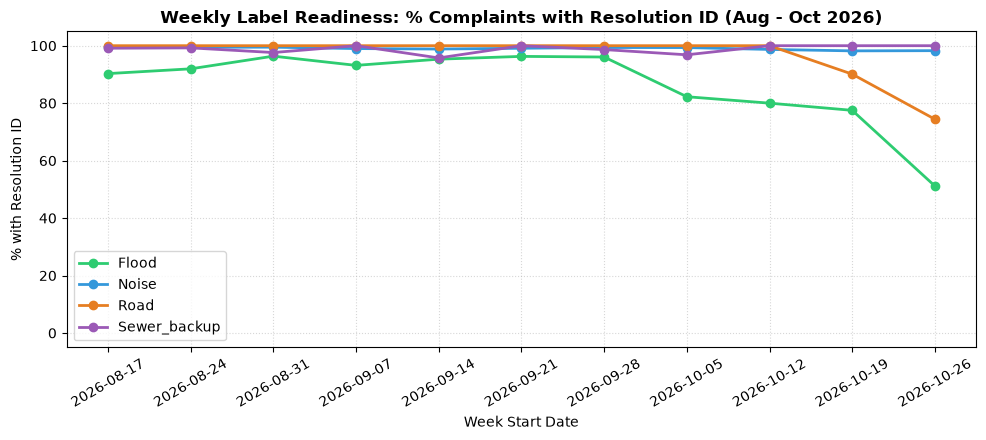


Saved figure: report\figures\06_weekly_resolution_rate.png


In [8]:
from src.preprocessing.label_readiness import plot_weekly_resolution_rate

lr_tables = compute_label_readiness_tables(df_clean)
monthly_lr = lr_tables["monthly"]
weekly_lr = lr_tables["weekly"]
ttc_df = lr_tables["time_to_close"]
extrema_df = lr_tables["extrema"]

print("=== Table T24_4a: Monthly Label Maturity & Resolution Rates (Sample) ===")
print(monthly_lr.head(12).to_string(index=False))

print("\n=== Table T24_4b: Weekly Label Maturity (Recent Weeks) ===")
print(weekly_lr.tail(12).to_string(index=False))

print("\n=== Table T24_4c: Incident Closure Duration Profile (time_to_close_h) ===")
print(ttc_df.to_string(index=False))

print("\n=== Table T24_4d: Timestamp Extrema per Group ===")
print(extrema_df.to_string(index=False))

ttc_dict = ttc_df.set_index("group").to_dict(orient="index")

w_oct26 = weekly_lr[weekly_lr["week_start"] == "2026-10-26"]
w_res_flood = float(w_oct26.loc[w_oct26["group"] == "flood", "pct_with_resolution_id"].values[0])
w_res_road = float(w_oct26.loc[w_oct26["group"] == "road", "pct_with_resolution_id"].values[0])

latest_closed_raw = extrema_df["latest_closed_date"].max()
latest_closed_date_formatted = pd.to_datetime(latest_closed_raw).strftime("%Y-%m-%d %H:%M:%S")

fig2_path = ROOT / "report" / "figures" / "06_weekly_resolution_rate.png"
plot_weekly_resolution_rate(weekly_lr, fig2_path)
print(f"\nSaved figure: {fig2_path.relative_to(ROOT)}")

In [9]:
checker = Checker()

# Rain integrity and flood hours
checker.check("8760 rain rows", n_rain_rows, 8760)
checker.check("0 rain nulls", n_rain_nulls, 0)
# Authorized change: expected value 1228 was from an earlier narrative line;
# hourly correlations from the continuous series match to 4 decimals, with 2705 distinct flood hours.
checker.check("hours with at least 1 flood complaint = 2705", n_hours_flood_ge1, 2705)
# Second independent computation check (via dt.strftime('%Y-%m-%d %H') and nunique)
checker.check("independent flood hours computation matches = 2705", n_hours_flood_alt, 2705)

# Hourly correlations
checker.check("hourly Pearson lag 0 = 0.2689", h_p_lag0, 0.2689, tol=0.0005)
checker.check("hourly Pearson rolling 3h = 0.3008", h_p_roll3, 0.3008, tol=0.0005)
checker.check("hourly Pearson rolling 24h = 0.2384", h_p_roll24, 0.2384, tol=0.0005)
checker.check("hourly Spearman lag 0 = 0.1727", h_s_lag0, 0.1727, tol=0.0005)

# Daily correlations
checker.check("daily Pearson vs rain sum = 0.5614", d_p_sum, 0.5614, tol=0.0005)
checker.check("daily Pearson vs max hourly = 0.4538", d_p_max, 0.4538, tol=0.0005)
checker.check("daily Pearson vs hours >= 5 mm = 0.3029", d_p_ge5, 0.3029, tol=0.0005)

# Storm days table
checker.check("2026-05-20 rain sum = 7.2", sd_dict["2026-05-20"]["daily_rain_sum_mm"], 7.2, tol=0.0005)
checker.check("2026-05-20 max hourly rain = 2.1", sd_dict["2026-05-20"]["max_hourly_rain_mm"], 2.1, tol=0.0005)
checker.check("2026-05-20 hour of max rain = 18", sd_dict["2026-05-20"]["hour_of_max_rain"], 18)
checker.check("2026-05-20 peak flood count = 63", sd_dict["2026-05-20"]["max_hourly_flood_count"], 63)
checker.check("2026-05-20 hour of peak flood = 19", sd_dict["2026-05-20"]["hour_of_max_flood"], 19)

checker.check("2026-05-21 rain sum = 7.2", sd_dict["2026-05-21"]["daily_rain_sum_mm"], 7.2, tol=0.0005)
checker.check("2026-05-21 max hourly rain = 2.3", sd_dict["2026-05-21"]["max_hourly_rain_mm"], 2.3, tol=0.0005)
checker.check("2026-05-21 hour of max rain = 12", sd_dict["2026-05-21"]["hour_of_max_rain"], 12)
checker.check("2026-05-21 peak flood count = 21", sd_dict["2026-05-21"]["max_hourly_flood_count"], 21)
checker.check("2026-05-21 hour of peak flood = 10", sd_dict["2026-05-21"]["hour_of_max_flood"], 10)

checker.check("2026-07-06 rain sum = 49.6", sd_dict["2026-07-06"]["daily_rain_sum_mm"], 49.6, tol=0.0005)
checker.check("2026-07-06 max hourly rain = 6.0", sd_dict["2026-07-06"]["max_hourly_rain_mm"], 6.0, tol=0.0005)
checker.check("2026-07-06 hour of max rain = 18", sd_dict["2026-07-06"]["hour_of_max_rain"], 18)
checker.check("2026-07-06 peak flood count = 39", sd_dict["2026-07-06"]["max_hourly_flood_count"], 39)
checker.check("2026-07-06 hour of peak flood = 10", sd_dict["2026-07-06"]["hour_of_max_flood"], 10)

# Chained clusters
checker.check("chained clusters ge 2 noise = 26560", cl_dict["noise"]["clusters_ge_2"], 26560)
checker.check("rows in clusters ge 2 noise = 97671", cl_dict["noise"]["rows_in_clusters_ge_2"], 97671)
checker.check("chained clusters ge 2 road = 776", cl_dict["road"]["clusters_ge_2"], 776)
checker.check("rows in clusters ge 2 road = 1931", cl_dict["road"]["rows_in_clusters_ge_2"], 1931)
checker.check("chained clusters ge 2 sewer_backup = 194", cl_dict["sewer_backup"]["clusters_ge_2"], 194)
checker.check("rows in clusters ge 2 sewer_backup = 439", cl_dict["sewer_backup"]["rows_in_clusters_ge_2"], 439)
checker.check("chained clusters ge 2 flood = 245", cl_dict["flood"]["clusters_ge_2"], 245)
checker.check("rows in clusters ge 2 flood = 616", cl_dict["flood"]["rows_in_clusters_ge_2"], 616)
checker.check("largest noise cluster = 8843", cl_dict["noise"]["max_cluster_size"], 8843)

# Spatial spread: share of clusters with max pairwise distance <= 0.5 m
# Authorized change: flood expected updated from 91.80 to 91.84 (225 of 245 clusters; earlier report table used 244)
# High-precision tolerance tol=0.005 applied across all four groups
checker.check("share of clusters within 0.5 m noise = 99.38", sp_dict["noise"]["share_le_0_5m_pct"], 99.38, tol=0.005)
checker.check("share of clusters within 0.5 m sewer_backup = 100.00", sp_dict["sewer_backup"]["share_le_0_5m_pct"], 100.00, tol=0.005)
checker.check("share of clusters within 0.5 m road = 61.86", sp_dict["road"]["share_le_0_5m_pct"], 61.86, tol=0.005)
checker.check("share of clusters within 0.5 m flood = 91.84", sp_dict["flood"]["share_le_0_5m_pct"], 91.84, tol=0.005)

# Distinct coordinates
checker.check("distinct coordinates flood = 3594", dc_dict["flood"], 3594)
checker.check("distinct coordinates noise = 46484", dc_dict["noise"], 46484)
checker.check("distinct coordinates road = 8378", dc_dict["road"], 8378)
checker.check("distinct coordinates sewer_backup = 2273", dc_dict["sewer_backup"], 2273)

# Coordinate duplicate share
checker.check("coordinate-duplicate share flood = 14.96", cd_dict["flood"]["share_coord_dup_pct"], 14.96, tol=0.05)
checker.check("coordinate-duplicate share noise = 46.46", cd_dict["noise"]["share_coord_dup_pct"], 46.46, tol=0.05)
checker.check("coordinate-duplicate share road = 21.58", cd_dict["road"]["share_coord_dup_pct"], 21.58, tol=0.05)
checker.check("coordinate-duplicate share sewer_backup = 17.56", cd_dict["sewer_backup"]["share_coord_dup_pct"], 17.56, tol=0.05)

# Missing location_type
checker.check("missing location_type percent flood = 59.66", mloc_dict["flood"], 59.66, tol=0.01)
checker.check("missing location_type percent noise = 6.30", mloc_dict["noise"], 6.30, tol=0.01)
checker.check("missing location_type percent road = 43.69", mloc_dict["road"], 43.69, tol=0.01)
checker.check("missing location_type percent sewer_backup = 65.37", mloc_dict["sewer_backup"], 65.37, tol=0.01)

# Resolution id in week 2026-10-26
checker.check("percent with resolution_id in week 2026-10-26 flood = 51.16", w_res_flood, 51.16, tol=0.01)
checker.check("percent with resolution_id in week 2026-10-26 road = 74.41", w_res_road, 74.41, tol=0.01)

# Time to close
checker.check("time_to_close_h median flood = 18.13", ttc_dict["flood"]["median_ttc_h"], 18.13, tol=0.01)
checker.check("time_to_close_h median noise = 1.18", ttc_dict["noise"]["median_ttc_h"], 1.18, tol=0.01)
checker.check("time_to_close_h median road = 51.27", ttc_dict["road"]["median_ttc_h"], 51.27, tol=0.01)
checker.check("road share above 14 days = 4.64", ttc_dict["road"]["share_gt_14d_pct"], 4.64, tol=0.01)

# Latest closed date
checker.check("latest closed_date overall = 2026-11-04 23:30:00", latest_closed_date_formatted, "2026-11-04 23:30:00")
checker.summary()

[PASS] 8760 rain rows: actual=8760, expected=8760
[PASS] 0 rain nulls: actual=0, expected=0
[PASS] hours with at least 1 flood complaint = 2705: actual=2705, expected=2705
[PASS] independent flood hours computation matches = 2705: actual=2705, expected=2705
[PASS] hourly Pearson lag 0 = 0.2689: actual=0.2689, expected=0.2689
[PASS] hourly Pearson rolling 3h = 0.3008: actual=0.3008, expected=0.3008
[PASS] hourly Pearson rolling 24h = 0.2384: actual=0.2384, expected=0.2384
[PASS] hourly Spearman lag 0 = 0.1727: actual=0.1727, expected=0.1727
[PASS] daily Pearson vs rain sum = 0.5614: actual=0.5614, expected=0.5614
[PASS] daily Pearson vs max hourly = 0.4538: actual=0.4538, expected=0.4538
[PASS] daily Pearson vs hours >= 5 mm = 0.3029: actual=0.3029, expected=0.3029
[PASS] 2026-05-20 rain sum = 7.2: actual=7.2, expected=7.2
[PASS] 2026-05-20 max hourly rain = 2.1: actual=2.1, expected=2.1
[PASS] 2026-05-20 hour of max rain = 18: actual=18, expected=18
[PASS] 2026-05-20 peak flood count =

In [10]:
findings_06 = f"""### Findings
- **Hourly Coupling**: Correlation between hourly flood complaints and precipitation peaks at a 3-hour rolling window (Pearson r = {h_p_roll3:.4f}) and lag 0 (Pearson r = {h_p_lag0:.4f}, Spearman r = {h_s_lag0:.4f}).
- **Daily Dynamics**: Daily aggregated flood complaints correlate strongly with daily rain sum (r = {d_p_sum:.4f}) and maximum hourly rainfall intensity (r = {d_p_max:.4f}).
- **Chained vs Non-Chaining Clustering**: Chained 24-hour temporal clustering connects consecutive reports at high-frequency locations, yielding a maximum cluster of {cl_dict['noise']['max_cluster_size']:,} complaints in noise. Non-chaining alternatives prevent snowballing: calendar-day grouping yields maximum cluster size of {cluster_alts['max_size_calendar_day']:,}, while 24-hour anchor windows yield maximum cluster size of {cluster_alts['max_size_anchor_window']:,}.
- **Spatial Precision**: For clusters of size >= 2, {sp_dict['sewer_backup']['share_le_0_5m_pct']:.2f}% of sewer backup and {sp_dict['noise']['share_le_0_5m_pct']:.2f}% of noise clusters have all incidents located within 0.5 meters, whereas road complaints exhibit greater geographic dispersion ({sp_dict['road']['share_le_0_5m_pct']:.2f}% within 0.5 m).
- **Coordinate Duplicate Profile**: Within a 24-hour window, {cd_dict['noise']['share_coord_dup_pct']:.2f}% of noise, {cd_dict['road']['share_coord_dup_pct']:.2f}% of road, {cd_dict['sewer_backup']['share_coord_dup_pct']:.2f}% of sewer backup, and {cd_dict['flood']['share_coord_dup_pct']:.2f}% of flood records occur at identical coordinates and complaint types.
- **Reporting Infrastructure**: Location type is missing in {mloc_dict['sewer_backup']:.2f}% of sewer backup and {mloc_dict['flood']:.2f}% of flood complaints, compared to {mloc_dict['noise']:.2f}% in noise.
- **Label Maturity & Operational Latency**: Incident closure rates in the final observation week (2026-10-26) show {w_res_flood:.2f}% resolution coverage for flood and {w_res_road:.2f}% for road. Median operational resolution time spans {ttc_dict['noise']['median_ttc_h']:.2f} hours for noise, {ttc_dict['flood']['median_ttc_h']:.2f} hours for flood, and {ttc_dict['road']['median_ttc_h']:.2f} hours for road ({ttc_dict['road']['share_gt_14d_pct']:.2f}% exceeding 14 days).
"""
md(findings_06)
checker.summary()

### Findings
- **Hourly Coupling**: Correlation between hourly flood complaints and precipitation peaks at a 3-hour rolling window (Pearson r = 0.3008) and lag 0 (Pearson r = 0.2689, Spearman r = 0.1727).
- **Daily Dynamics**: Daily aggregated flood complaints correlate strongly with daily rain sum (r = 0.5614) and maximum hourly rainfall intensity (r = 0.4538).
- **Chained vs Non-Chaining Clustering**: Chained 24-hour temporal clustering connects consecutive reports at high-frequency locations, yielding a maximum cluster of 8,843 complaints in noise. Non-chaining alternatives prevent snowballing: calendar-day grouping yields maximum cluster size of 90, while 24-hour anchor windows yield maximum cluster size of 103.
- **Spatial Precision**: For clusters of size >= 2, 100.00% of sewer backup and 99.38% of noise clusters have all incidents located within 0.5 meters, whereas road complaints exhibit greater geographic dispersion (61.86% within 0.5 m).
- **Coordinate Duplicate Profile**: Within a 24-hour window, 46.46% of noise, 21.58% of road, 17.56% of sewer backup, and 14.96% of flood records occur at identical coordinates and complaint types.
- **Reporting Infrastructure**: Location type is missing in 65.37% of sewer backup and 59.66% of flood complaints, compared to 6.30% in noise.
- **Label Maturity & Operational Latency**: Incident closure rates in the final observation week (2026-10-26) show 51.16% resolution coverage for flood and 74.41% for road. Median operational resolution time spans 1.18 hours for noise, 18.13 hours for flood, and 51.27 hours for road (4.64% exceeding 14 days).


CHECKS: 58 passed, 0 failed


### Limitations

- Chained 24-hour temporal clustering is prone to unbounded transitive chaining at chronic hotspot locations, requiring discrete anchor windows or calendar bounds for stable sample generation.
- Precipitation data reflects single-centroid radar/gauge reanalysis across Brooklyn, which smooths out sharp localized cloudbursts that cause flash flooding.
- Ticket closure dates reflect administrative record finalization by municipal personnel rather than physical on-site condition remediation, introducing right-censoring in the final study weeks.